# Lab 7 — Bài tập mục 8

Nguyễn Đình Huy — MSSV: 2474802010140

Mỗi mục/bài có đúng một cell code. Giữ hai CSV trong `data/`, chạy từ thư mục Lab hoặc `code/`. Trên Colab có thể tải hai CSV vào thư mục hiện tại. Hình lưu ở `figures/`; chạy `scripts/run_all.py` để cập nhật notebook và xuất nhật ký ở `outputs/`.

## Bài tập 1 — Tự viết hàm đánh giá

In [1]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien_bo_hoc.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def danh_gia(y_that, y_doan):
    """Đánh giá nhị phân, lớp dương là 1; mẫu số 0 được quy ước trả 0."""
    that = np.asarray(y_that)
    doan = np.asarray(y_doan)
    if that.ndim != 1 or that.shape != doan.shape or that.size == 0:
        raise ValueError("Hai mảng phải một chiều, cùng kích thước và không rỗng.")
    if not np.all(np.isin(that, [0, 1])) or not np.all(np.isin(doan, [0, 1])):
        raise ValueError("Hàm này dành cho nhãn nhị phân 0 và 1.")
    tp = np.sum((that == 1) & (doan == 1))
    fp = np.sum((that == 0) & (doan == 1))
    fn = np.sum((that == 1) & (doan == 0))
    tn = np.sum((that == 0) & (doan == 0))
    accuracy = (tp + tn) / that.size
    precision = tp / (tp + fp) if tp + fp > 0 else 0.0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn > 0 else 0.0
    return accuracy, precision, recall, f1

df = pd.read_csv(tep_du_lieu("sinh_vien_bo_hoc.csv"))
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

cac_mo_hinh = {
    "Logistic": make_pipeline(StandardScaler(), LogisticRegression()),
    "Mô hình lười": DummyClassifier(strategy="most_frequent"),
}
print("Thứ tự: accuracy, precision, recall, F1")
for ten, mh in cac_mo_hinh.items():
    du = mh.fit(X_tr, y_tr).predict(X_te)
    tu_tinh = danh_gia(y_te, du)
    thu_vien = (accuracy_score(y_te, du), precision_score(y_te, du, zero_division=0),
                recall_score(y_te, du, zero_division=0), f1_score(y_te, du, zero_division=0))
    print(f"{ten} — NumPy:      " + ", ".join(f"{diem:.4f}" for diem in tu_tinh))
    print(f"{ten} — thư viện:   " + ", ".join(f"{diem:.4f}" for diem in thu_vien))
    assert np.allclose(tu_tinh, thu_vien)
print("Mô hình lười không đoán ai bỏ học, nên TP+FP=0 và precision theo công thức không xác định (0/0).")
print("Hàm quy ước precision bằng 0 khi mẫu số bằng 0, giống zero_division=0; đây là quy ước xử lý, không phải phép chia 0/0 có giá trị 0.")
print("Recall hoặc F1 có mẫu số 0 cũng được xử lý tương tự. Accuracy 0.9 của mô hình lười vẫn đi cùng recall 0 vì bỏ sót toàn bộ lớp dương.")


Thứ tự: accuracy, precision, recall, F1
Logistic — NumPy:      0.9467, 0.8500, 0.5667, 0.6800
Logistic — thư viện:   0.9467, 0.8500, 0.5667, 0.6800
Mô hình lười — NumPy:      0.9000, 0.0000, 0.0000, 0.0000
Mô hình lười — thư viện:   0.9000, 0.0000, 0.0000, 0.0000
Mô hình lười không đoán ai bỏ học, nên TP+FP=0 và precision theo công thức không xác định (0/0).
Hàm quy ước precision bằng 0 khi mẫu số bằng 0, giống zero_division=0; đây là quy ước xử lý, không phải phép chia 0/0 có giá trị 0.
Recall hoặc F1 có mẫu số 0 cũng được xử lý tương tự. Accuracy 0.9 của mô hình lười vẫn đi cùng recall 0 vì bỏ sót toàn bộ lớp dương.


## Bài tập 2 — Đánh giá từng chữ số viết tay

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        45
           1     0.9787    1.0000    0.9892        46
           2     1.0000    1.0000    1.0000        44
           3     0.9787    1.0000    0.9892        46
           4     1.0000    0.9778    0.9888        45
           5     1.0000    1.0000    1.0000        46
           6     1.0000    1.0000    1.0000        45
           7     1.0000    0.9778    0.9888        45
           8     0.9767    0.9767    0.9767        43
           9     0.9778    0.9778    0.9778        45

    accuracy                         0.9911       450
   macro avg     0.9912    0.9910    0.9911       450
weighted avg     0.9912    0.9911    0.9911       450

Recall thấp nhất: chữ số 8, giá trị 0.9767.
Precision thấp nhất: chữ số 8, giá trị 0.9767.
Số ảnh mỗi lớp trong tập kiểm tra: từ 43 đến 46.
Macro avg cho mỗi lớp trọng số bằng nhau; weighted avg lấy trọng số theo số ảnh. Số ảnh của 10 lớp gầ

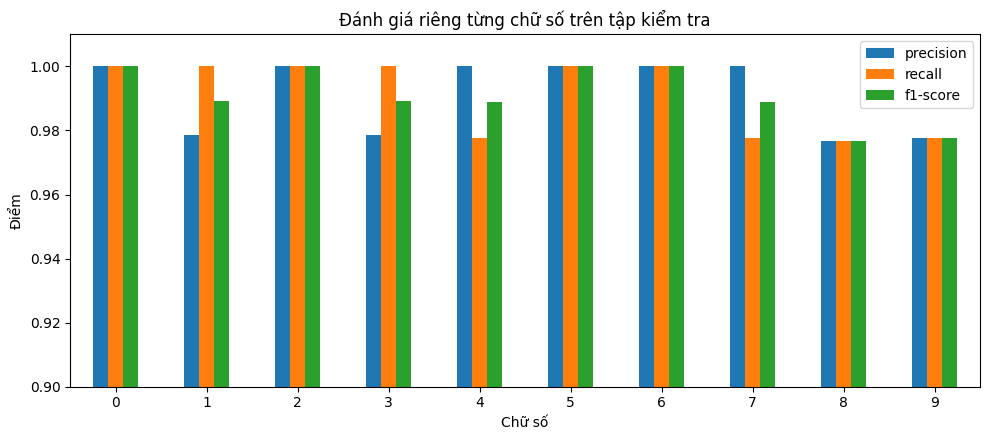

In [2]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien_bo_hoc.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
# Đúng mô hình SVM RBF không chuẩn hóa của Lab 6.
svm = SVC(kernel="rbf").fit(X_tr, y_tr)
du = svm.predict(X_te)
print(classification_report(y_te, du, digits=4, zero_division=0))
bao_cao = classification_report(y_te, du, output_dict=True, zero_division=0)
bang = pd.DataFrame({str(i): bao_cao[str(i)] for i in range(10)}).T
for thuoc_do in ["recall", "precision"]:
    muc_thap = bang[thuoc_do].min()
    cac_chu_so = bang.index[np.isclose(bang[thuoc_do], muc_thap)].tolist()
    print(f"{thuoc_do.capitalize()} thấp nhất: chữ số {', '.join(cac_chu_so)}, giá trị {muc_thap:.4f}.")
print(f"Số ảnh mỗi lớp trong tập kiểm tra: từ {int(bang['support'].min())} đến {int(bang['support'].max())}.")
print("Macro avg cho mỗi lớp trọng số bằng nhau; weighted avg lấy trọng số theo số ảnh. Số ảnh của 10 lớp gần bằng nhau nên hai trung bình gần như bằng nhau.")
bang[["precision", "recall", "f1-score"]].plot.bar(rot=0, figsize=(10, 4.5))
plt.xlabel("Chữ số")
plt.ylabel("Điểm")
plt.title("Đánh giá riêng từng chữ số trên tập kiểm tra")
plt.ylim(.9, 1.01)

plt.tight_layout()
plt.savefig(thu_muc_hinh / "bao_cao_chu_so.png", dpi=150)
plt.show()
plt.close()


## Bài tập 3 — Chọn ngưỡng để recall ít nhất 80%

Ngưỡng lớn nhất có recall OOF >= 0.8: 0.171773644908
Recall OOF tại ngưỡng này: 0.8090
Số ca bỏ học phát hiện trên tập học ngoài fold: 72/89
Nếu chỉ xét lưới bước 0.05 của mục 5, ngưỡng lớn nhất là 0.15.
Tập kiểm tra: recall = 0.8000, precision = 0.5106, số bạn bị báo = 47.
Recall kiểm tra đạt 0.8: True
Ngưỡng được chọn hoàn toàn từ dự đoán ngoài fold trên tập học. Điều kiện recall OOF >= 0.8 không bảo đảm mọi tập dữ liệu mới đều đạt 0.8; không sửa lại ngưỡng sau khi xem kết quả kiểm tra.


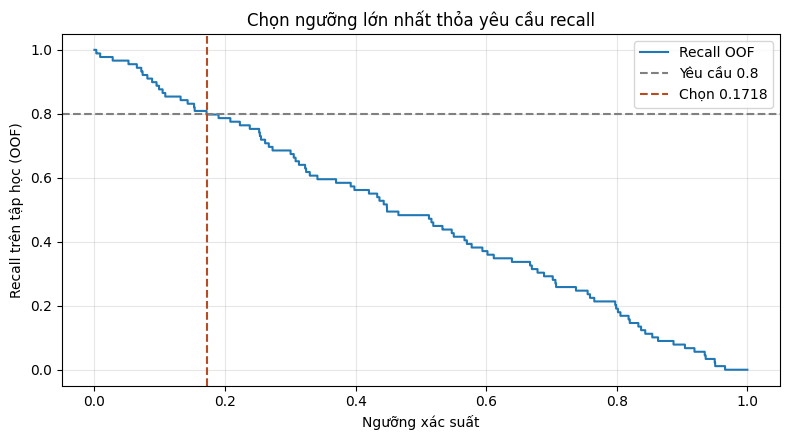

In [3]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien_bo_hoc.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import recall_score, precision_score
df = pd.read_csv(tep_du_lieu("sinh_vien_bo_hoc.csv"))
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
lr = make_pipeline(StandardScaler(), LogisticRegression())

# Không nhìn xác suất hoặc nhãn kiểm tra trong bước chọn ngưỡng.
xs_oof = cross_val_predict(lr, X_tr, y_tr, cv=5, method="predict_proba")[:, 1]
# Recall chỉ thay đổi khi vượt một xác suất dự đoán. Thử mọi mức khác nhau
# để tìm ngưỡng lớn nhất, không bị giới hạn bởi bước lưới 0.05.
cac_nguong = np.unique(np.r_[0.0, xs_oof, 1.0])
recall_oof = np.array([recall_score(y_tr, xs_oof >= t, zero_division=0) for t in cac_nguong])
t_tot = cac_nguong[recall_oof >= 0.8].max()
print(f"Ngưỡng lớn nhất có recall OOF >= 0.8: {t_tot:.12f}")
print(f"Recall OOF tại ngưỡng này: {recall_score(y_tr, xs_oof >= t_tot):.4f}")
print(f"Số ca bỏ học phát hiện trên tập học ngoài fold: {np.sum((xs_oof >= t_tot) & (y_tr.to_numpy() == 1))}/{int(y_tr.sum())}")
# Mốc tham khảo theo đúng lưới thưa của mục 5, vẫn chỉ dùng tập học.
luoi_muc_5 = np.round(np.arange(.05, .96, .05), 2)
t_luoi = max(t for t in luoi_muc_5 if recall_score(y_tr, xs_oof >= t) >= .8)
print(f"Nếu chỉ xét lưới bước 0.05 của mục 5, ngưỡng lớn nhất là {t_luoi:.2f}.")

# Chốt ngưỡng rồi fit toàn bộ tập học và đánh giá kiểm tra đúng một lần.
lr.fit(X_tr, y_tr)
xs_kiem_tra = lr.predict_proba(X_te)[:, 1]
du = (xs_kiem_tra >= t_tot).astype(int)
recall_kiem_tra = recall_score(y_te, du)
print(f"Tập kiểm tra: recall = {recall_kiem_tra:.4f}, precision = {precision_score(y_te, du, zero_division=0):.4f}, số bạn bị báo = {du.sum()}.")
print("Recall kiểm tra đạt 0.8:", recall_kiem_tra >= .8)
print("Ngưỡng được chọn hoàn toàn từ dự đoán ngoài fold trên tập học. Điều kiện recall OOF >= 0.8 không bảo đảm mọi tập dữ liệu mới đều đạt 0.8; không sửa lại ngưỡng sau khi xem kết quả kiểm tra.")
plt.figure(figsize=(8, 4.5))
plt.step(cac_nguong, recall_oof, where="pre", label="Recall OOF")
plt.axhline(.8, color="gray", linestyle="--", label="Yêu cầu 0.8")
plt.axvline(t_tot, color="#b64c24", linestyle="--", label=f"Chọn {t_tot:.4f}")
plt.xlabel("Ngưỡng xác suất")
plt.ylabel("Recall trên tập học (OOF)")
plt.title("Chọn ngưỡng lớn nhất thỏa yêu cầu recall")
plt.legend()
plt.grid(alpha=.3)

plt.tight_layout()
plt.savefig(thu_muc_hinh / "nguong_recall_80.png", dpi=150)
plt.show()
plt.close()


## Bài tập 4 — Tự vẽ đường ROC

Logistic: AUC = 0.9449


Rừng 200 cây: AUC = 0.9249


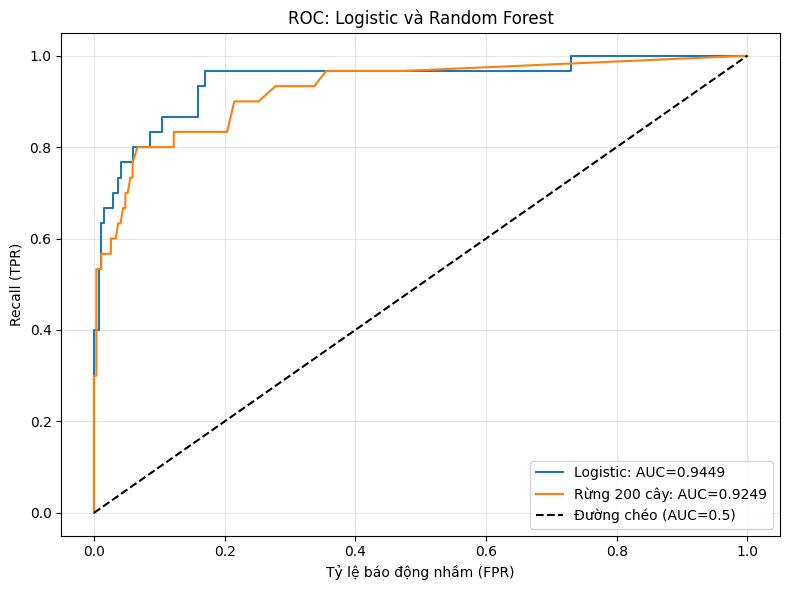

Xét tổng thể bằng AUC, Logistic ôm góc trên trái tốt hơn; AUC cao hơn không có nghĩa luôn cao hơn ở mọi FPR.
Hai đường có đổi vị trí cao/thấp (cắt nhau): True
Ví dụ Logistic cao hơn ở đoạn FPR (0.0000, 0.0037).
Ví dụ Rừng cao hơn ở đoạn FPR (0.0037, 0.0074).
Chọn mô hình và ngưỡng còn phụ thuộc mức báo nhầm chấp nhận được, không chỉ nhìn một con số AUC.


In [4]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien_bo_hoc.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score
df = pd.read_csv(tep_du_lieu("sinh_vien_bo_hoc.csv"))
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

cac_mo_hinh = {
    "Logistic": make_pipeline(StandardScaler(), LogisticRegression()),
    "Rừng 200 cây": RandomForestClassifier(200, random_state=0),
}
duong_roc = {}
plt.figure(figsize=(8, 6))
for ten, mh in cac_mo_hinh.items():
    xs = mh.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, xs)
    auc = roc_auc_score(y_te, xs)
    duong_roc[ten] = (fpr, tpr, auc)
    plt.plot(fpr, tpr, label=f"{ten}: AUC={auc:.4f}")
    print(f"{ten}: AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], "k--", label="Đường chéo (AUC=0.5)")
plt.xlabel("Tỷ lệ báo động nhầm (FPR)")
plt.ylabel("Recall (TPR)")
plt.title("ROC: Logistic và Random Forest")
plt.legend(loc="lower right")
plt.grid(alpha=.3)

plt.tight_layout()
plt.savefig(thu_muc_hinh / "roc.png", dpi=150)
plt.show()
plt.close()

tot = max(duong_roc, key=lambda ten: duong_roc[ten][2])
print(f"Xét tổng thể bằng AUC, {tot} ôm góc trên trái tốt hơn; AUC cao hơn không có nghĩa luôn cao hơn ở mọi FPR.")
# Nội suy trong từng khoảng FPR để kiểm tra đường nào cao hơn, tránh
# so hai mảng ROC có số điểm và ngưỡng khác nhau theo cùng chỉ số.
fpr_lr, tpr_lr, _ = duong_roc["Logistic"]
fpr_rf, tpr_rf, _ = duong_roc["Rừng 200 cây"]
moc = np.unique(np.r_[fpr_lr, fpr_rf])
giua = (moc[:-1] + moc[1:]) / 2
chenh = np.interp(giua, fpr_lr, tpr_lr) - np.interp(giua, fpr_rf, tpr_rf)
co_doi_vi_tri = np.any(chenh > 1e-10) and np.any(chenh < -1e-10)
print("Hai đường có đổi vị trí cao/thấp (cắt nhau):", co_doi_vi_tri)
for nhan, dieu_kien in [("Logistic cao hơn", chenh > 1e-10), ("Rừng cao hơn", chenh < -1e-10)]:
    vi_tri = np.flatnonzero(dieu_kien)
    if len(vi_tri):
        i = vi_tri[0]
        print(f"Ví dụ {nhan} ở đoạn FPR ({moc[i]:.4f}, {moc[i + 1]:.4f}).")
print("Chọn mô hình và ngưỡng còn phụ thuộc mức báo nhầm chấp nhận được, không chỉ nhìn một con số AUC.")


## Bài tập 5 — Cân bằng lớp cho rừng và SVM

So sánh chính — dùng predict như mục 7:
      mo_hinh class_weight  precision  recall     F1
Random Forest         None     0.7727  0.5667 0.6538
Random Forest     balanced     0.7500  0.4000 0.5217
      SVM RBF         None     0.8824  0.5000 0.6383
      SVM RBF     balanced     0.4464  0.8333 0.5814
Random Forest, balanced - thường: precision -0.0227, recall -0.1667, F1 -0.1321.
SVM RBF, balanced - thường: precision -0.4359, recall +0.3333, F1 -0.0569.
Xét độ thay đổi tuyệt đối của recall, SVM RBF thay đổi nhiều nhất.
Cân bằng lớp thay đổi mức phạt lúc học, không bảo đảm mọi thước đo đều tăng. Trong lần chia này SVM tăng recall nhưng giảm precision; rừng lại giảm recall.
Bảng bổ sung — dùng predict_proba >= 0.5 như mục 6:
      mo_hinh class_weight  precision  recall     F1
Random Forest         None     0.7727  0.5667 0.6538
Random Forest     balanced     0.7647  0.4333 0.5532
      SVM RBF         None     0.8333  0.5000 0.6250
      SVM RBF     balanced     0.8125  0.4333 0.5652

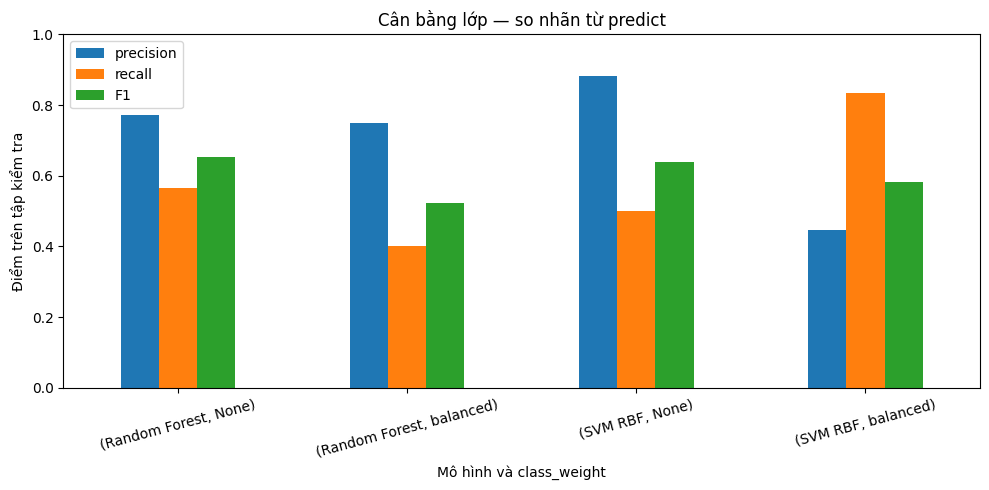

In [5]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien_bo_hoc.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import precision_score, recall_score, f1_score
df = pd.read_csv(tep_du_lieu("sinh_vien_bo_hoc.csv"))
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

ket_qua = []
ket_qua_xac_suat = []
for ten in ["Random Forest", "SVM RBF"]:
    for trong_so in [None, "balanced"]:
        if ten == "Random Forest":
            mh = RandomForestClassifier(200, random_state=0, class_weight=trong_so)
        else:
            mh = make_pipeline(StandardScaler(), SVC(probability=True, random_state=0, class_weight=trong_so))
        mh.fit(X_tr, y_tr)
        # So bằng predict như mục 7: giữ nguyên mọi thứ ngoài class_weight.
        du = mh.predict(X_te)
        ket_qua.append({"mo_hinh": ten, "class_weight": str(trong_so),
                        "precision": precision_score(y_te, du, zero_division=0),
                        "recall": recall_score(y_te, du, zero_division=0),
                        "F1": f1_score(y_te, du, zero_division=0)})
        # Bảng bổ sung cùng quy tắc xác suất >=0.5 của mục 6 để tránh
        # nhầm predict của SVM với ngưỡng xác suất đã hiệu chỉnh.
        du_xs = (mh.predict_proba(X_te)[:, 1] >= .5).astype(int)
        ket_qua_xac_suat.append({"mo_hinh": ten, "class_weight": str(trong_so),
                                 "precision": precision_score(y_te, du_xs, zero_division=0),
                                 "recall": recall_score(y_te, du_xs, zero_division=0),
                                 "F1": f1_score(y_te, du_xs, zero_division=0)})
bang = pd.DataFrame(ket_qua)
print("So sánh chính — dùng predict như mục 7:")
print(bang.round(4).to_string(index=False))
chenh_lech = {}
for ten in bang.mo_hinh.unique():
    nhom = bang[bang.mo_hinh == ten].set_index("class_weight")
    doi = nhom.loc["balanced", ["precision", "recall", "F1"]] - nhom.loc["None", ["precision", "recall", "F1"]]
    chenh_lech[ten] = abs(doi["recall"])
    print(f"{ten}, balanced - thường: precision {doi['precision']:+.4f}, recall {doi['recall']:+.4f}, F1 {doi['F1']:+.4f}.")
print(f"Xét độ thay đổi tuyệt đối của recall, {max(chenh_lech, key=chenh_lech.get)} thay đổi nhiều nhất.")
print("Cân bằng lớp thay đổi mức phạt lúc học, không bảo đảm mọi thước đo đều tăng. Trong lần chia này SVM tăng recall nhưng giảm precision; rừng lại giảm recall.")
print("Bảng bổ sung — dùng predict_proba >= 0.5 như mục 6:")
print(pd.DataFrame(ket_qua_xac_suat).round(4).to_string(index=False))
print("predict của SVM dùng ranh giới quyết định; xác suất được hiệu chỉnh riêng nên ngưỡng 0.5 có thể cho nhãn khác. Rừng cũng có thể khác ở trường hợp xác suất đúng 0.5 vì cách xử lý hòa.")
print("Vì vậy kết luận thay đổi nhiều nhất ở trên áp dụng cho bảng predict; cần giữ cùng quy tắc quyết định khi so sánh.")
bang.set_index(["mo_hinh", "class_weight"])[["precision", "recall", "F1"]].plot.bar(rot=15, figsize=(10, 5))
plt.xlabel("Mô hình và class_weight")
plt.ylabel("Điểm trên tập kiểm tra")
plt.title("Cân bằng lớp — so nhãn từ predict")
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig(thu_muc_hinh / "can_bang_rung_svm.png", dpi=150)
plt.show()
plt.close()


## Bài tập 6 — MAE, RMSE và một dự đoán hỏng

Căn sửa dự đoán: chỉ số dữ liệu 0, diện tích 35.5 m².
Giá thật 3.0000; dự đoán ban đầu 3.2179; sau cộng 5 tỷ 8.2179.
MAE, RMSE có đơn vị tỷ đồng; R² không có đơn vị:
                        MAE      RMSE        R2
truong_hop                                     
Ban đầu            0.257784  0.373041  0.962229
Một dự đoán +5 tỷ  0.674451  1.550516  0.347467
Thay đổi sau - trước:
MAE     0.416667
RMSE    1.177475
R2     -0.614761
MAE tăng 2.62 lần; RMSE tăng 4.16 lần.
Nếu chỉ xét độ lớn thay đổi số học của ba con số, RMSE thay đổi nhiều nhất trong lần thử này.
So hai sai số cùng đơn vị, RMSE tăng mạnh hơn MAE: RMSE bình phương sai số trước khi lấy trung bình rồi căn bậc hai, nên sai số lớn có trọng số ảnh hưởng mạnh hơn.
R² giảm vì tổng bình phương sai số tăng; không nên so trực tiếp độ lớn R² với MAE/RMSE vì khác đơn vị và ý nghĩa.


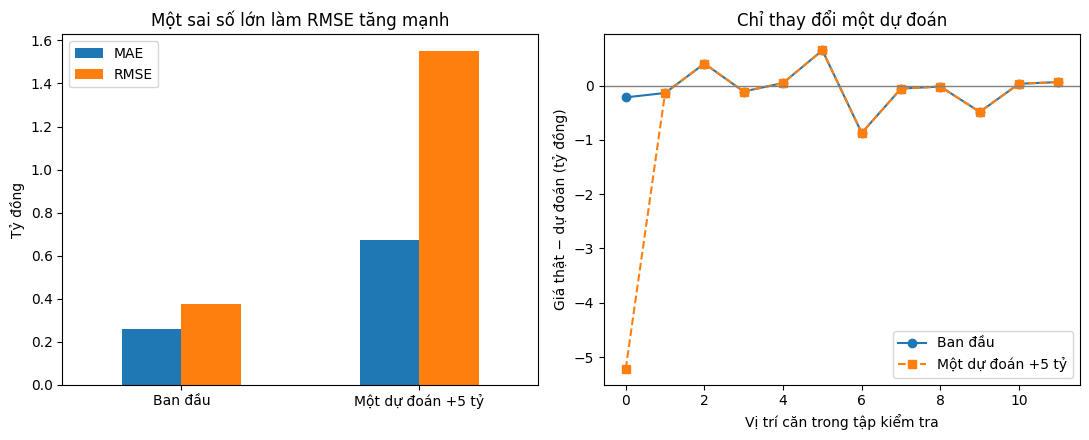

In [6]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien_bo_hoc.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv(tep_du_lieu("gia_nha.csv"))
X = df[["dien_tich"]]
y = df["gia"]
# Giữ mô hình một biến và cách chia của Lab 1.
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.2, random_state=42)
mh = LinearRegression().fit(X_tr, y_tr)
gia_du_doan = mh.predict(X_te)
gia_hong = gia_du_doan.copy()
gia_hong[0] += 5  # Chỉ cộng 5 tỷ vào dự đoán căn đầu tiên của tập kiểm tra.
print(f"Căn sửa dự đoán: chỉ số dữ liệu {X_te.index[0]}, diện tích {X_te.iloc[0, 0]:.1f} m².")
print(f"Giá thật {y_te.iloc[0]:.4f}; dự đoán ban đầu {gia_du_doan[0]:.4f}; sau cộng 5 tỷ {gia_hong[0]:.4f}.")
ket_qua = []
for ten, gia in [("Ban đầu", gia_du_doan), ("Một dự đoán +5 tỷ", gia_hong)]:
    ket_qua.append({"truong_hop": ten, "MAE": mean_absolute_error(y_te, gia),
                    "RMSE": np.sqrt(mean_squared_error(y_te, gia)), "R2": r2_score(y_te, gia)})
bang = pd.DataFrame(ket_qua).set_index("truong_hop")
print("MAE, RMSE có đơn vị tỷ đồng; R² không có đơn vị:")
print(bang.round(6).to_string())
doi = bang.iloc[1] - bang.iloc[0]
print("Thay đổi sau - trước:")
print(doi.round(6).to_string())
print(f"MAE tăng {bang.iloc[1]['MAE'] / bang.iloc[0]['MAE']:.2f} lần; RMSE tăng {bang.iloc[1]['RMSE'] / bang.iloc[0]['RMSE']:.2f} lần.")
print(f"Nếu chỉ xét độ lớn thay đổi số học của ba con số, {doi.abs().idxmax()} thay đổi nhiều nhất trong lần thử này.")
print("So hai sai số cùng đơn vị, RMSE tăng mạnh hơn MAE: RMSE bình phương sai số trước khi lấy trung bình rồi căn bậc hai, nên sai số lớn có trọng số ảnh hưởng mạnh hơn.")
print("R² giảm vì tổng bình phương sai số tăng; không nên so trực tiếp độ lớn R² với MAE/RMSE vì khác đơn vị và ý nghĩa.")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
bang[["MAE", "RMSE"]].plot.bar(ax=axes[0], rot=0)
axes[0].set(xlabel="", ylabel="Tỷ đồng", title="Một sai số lớn làm RMSE tăng mạnh")
axes[1].plot(np.arange(len(y_te)), y_te.to_numpy() - gia_du_doan, "o-", label="Ban đầu")
axes[1].plot(np.arange(len(y_te)), y_te.to_numpy() - gia_hong, "s--", label="Một dự đoán +5 tỷ")
axes[1].axhline(0, color="gray", linewidth=1)
axes[1].set(xlabel="Vị trí căn trong tập kiểm tra", ylabel="Giá thật − dự đoán (tỷ đồng)", title="Chỉ thay đổi một dự đoán")
axes[1].legend()

plt.tight_layout()
plt.savefig(thu_muc_hinh / "mae_rmse_du_doan_hong.png", dpi=150)
plt.show()
plt.close()
